# 06 · Revisión del día 7: tercer modelo y partición balanceada
Observaciones del profesor en el control y cómo se atienden:

| Observación | Qué se hace aquí |
|---|---|
| Tercer modelo | **E4 = ResNet50** congelada, mismo protocolo que E1 y E3 |
| Verificar el formato de las imágenes | Formato, modo de color y peso por clase (sección 1) |
| Resolución de las imágenes | Tamaños encontrados (sección 1) |
| 8.000 imágenes / 1.000 bien repartidas | Prueba nueva de **1.000 balanceada (200 por clase)**, validación de 200 por clase y entrenamiento con el resto (sección 2) |
| Verificar que no sea el mismo dataset | Control de que ninguna foto de prueba (ni casi igual) esté en entrenamiento (sección 2) |

Necesita GPU (T4). Las hipótesis de E4 están en `docs/03_hipotesis.md` desde antes de ejecutar.
Los resultados se guardan con prefijo `B_` (B_E0 … B_E4) y no reemplazan los de la partición original.

In [2]:
# PREPARACIÓN
from google.colab import drive
drive.mount('/content/drive')
PROYECTO = '/content/drive/MyDrive/yuca-comparacion-final/yuca-comparacion'
import os, sys
os.chdir(PROYECTO); sys.path.insert(0, PROYECTO)
from src.datos import descargar_dataset
RAIZ = str(descargar_dataset(destino='/content/datos', carpeta_zip=PROYECTO + '/data'))
os.environ['YUCA_DATOS'] = RAIZ
import torch
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'SIN GPU (Entorno de ejecución > Cambiar tipo > T4 GPU)')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[1/2] Ya existe el archivo /content/drive/MyDrive/yuca-comparacion-final/yuca-comparacion/data/cassavaleafdata.zip; no se descarga de nuevo.
[2/2] Descomprimiendo...
[ok] Dataset listo en: /content/datos/cassavaleafdata
GPU: Tesla T4


## 1. Formato y resolución de las imágenes

In [3]:
import pandas as pd
inv = pd.read_csv('resultados/inventario.csv')
print('Imágenes:', len(inv))
print('Formatos:', inv['ruta'].str.extract(r'\.(\w+)$')[0].str.lower().value_counts().to_dict())
print('Modo de color:', inv['modo'].value_counts().to_dict())
print('Tamaños distintos:', inv.groupby(['ancho','alto']).ngroups)
print('Menores a 224 px:', int(((inv.ancho < 224) | (inv.alto < 224)).sum()))
display(inv.groupby(['ancho','alto']).size().sort_values(ascending=False).head(8).rename('imágenes').to_frame())
inv['megapixeles'] = inv.ancho * inv.alto / 1e6
inv['KB'] = inv.bytes / 1024
inv.groupby('clase')[['megapixeles','KB']].median().round(2)

Imágenes: 9430
Formatos: {'jpg': 9430}
Modo de color: {'RGB': 9430}
Tamaños distintos: 669
Menores a 224 px: 0


imágenes
ancho alto          
500   666       2369
888   500       1328
625   500       1073
666   500       1070
500   500        719
      888        512
499   500         46
623   500         18

,megapixeles,KB
clase,,
cbb,0.31,95.67
cbsd,0.33,134.25
cgm,0.33,120.48
cmd,0.33,162.90
healthy,0.31,61.35


## 2. Partición balanceada
Reglas: fotos idénticas o casi idénticas forman un grupo que va entero a una sola partición; los grupos con etiquetas
distintas se retiran completos; de cada grupo se conserva una copia. Luego, por clase y con semilla 42: 200 a prueba, 200 a
validación y el resto a entrenamiento.

In [4]:
from src.particion import crear_particion_balanceada, verificar_sin_fugas, RUTA_SALIDA
casi = pd.read_csv('resultados/eda/casi_duplicados.csv')
nueva, resumen = crear_particion_balanceada(inv, casi, por_clase_prueba=200, por_clase_validacion=200, semilla=42)
nueva.to_csv(RUTA_SALIDA, index=False)
print(resumen)
grupos_cruzados, md5_cruzados = verificar_sin_fugas(nueva)
print('Grupos repartidos entre particiones:', grupos_cruzados, '| archivos idénticos repartidos:', md5_cruzados, '(deben ser 0)')
pd.crosstab(nueva['clase'], nueva['particion_nueva'], margins=True)

{'imagenes_iniciales': 9430, 'retiradas_por_etiqueta_contradictoria': 63, 'copias_retiradas': 30, 'imagenes_finales': 9337}
Grupos repartidos entre particiones: 0 | archivos idénticos repartidos: 0 (deben ser 0)


particion_nueva,test,train,validation,All
clase,,,,
cbb,200,358,200,758
cbsd,200,1969,200,2369
cgm,200,871,200,1271
cmd,200,4015,200,4415
healthy,200,124,200,524
All,1000,7337,1000,9337


## 3. Experimentos E0 a E4 en la partición balanceada (semilla 42)
Orden: E0, E1, E3, E4 y al final E2 (que parte del mejor E1). Tarda alrededor de 1 hora.

In [5]:
from src.comun import cargar_config
from src.entrenar import ejecutar
cfg = cargar_config()
cfg['protocolo']['particion'] = 'balanceada'   # no se modifica el archivo de configuración
resultados = {}
for exp in ['E0', 'E1', 'E3', 'E4', 'E2']:
    resultados[exp] = ejecutar(exp, cfg=cfg)

[2026-11-25 04:18:56] === B_E0: Baseline sin preentrenamiento ===
[2026-11-25 04:18:56] Dispositivo: Tesla T4 | semilla: 42
[2026-11-25 04:18:56] Partición: balanceada
[2026-11-25 04:18:56] Imágenes: train=7337 val=1000 test=1000
[2026-11-25 04:18:56] Parámetros: 24,133 totales, 24,133 entrenables, 0.1 MB
[2026-11-25 04:19:37] Época  1/10 | train pérdida 1.5108 F1 0.2746 | val pérdida 1.4635 F1 0.3119 acc 0.3510  <- mejor hasta ahora (guardado)
[2026-11-25 04:20:14] Época  2/10 | train pérdida 1.4085 F1 0.3328 | val pérdida 1.4138 F1 0.3783 acc 0.3930  <- mejor hasta ahora (guardado)
[2026-11-25 04:20:52] Época  3/10 | train pérdida 1.3593 F1 0.3416 | val pérdida 1.4175 F1 0.3838 acc 0.4080  <- mejor hasta ahora (guardado)
[2026-11-25 04:21:29] Época  4/10 | train pérdida 1.3408 F1 0.3467 | val pérdida 1.2885 F1 0.4006 acc 0.4090  <- mejor hasta ahora (guardado)
[2026-11-25 04:22:07] Época  5/10 | train pérdida 1.3245 F1 0.3599 | val pérdida 1.3127 F1 0.4006 acc 0.4240  <- mejor hasta 

100%|██████████| 44.7M/44.7M [00:00<00:00, 194MB/s]


[2026-11-25 04:25:16] Parámetros: 11,179,077 totales, 2,565 entrenables, 44.75 MB
[2026-11-25 04:26:15] Época  1/10 | train pérdida 1.2909 F1 0.3872 | val pérdida 1.0530 F1 0.6063 acc 0.6100  <- mejor hasta ahora (guardado)
[2026-11-25 04:27:14] Época  2/10 | train pérdida 0.9971 F1 0.5099 | val pérdida 0.9229 F1 0.6607 acc 0.6630  <- mejor hasta ahora (guardado)
[2026-11-25 04:28:13] Época  3/10 | train pérdida 0.9361 F1 0.5319 | val pérdida 0.8899 F1 0.6781 acc 0.6860  <- mejor hasta ahora (guardado)
[2026-11-25 04:29:12] Época  4/10 | train pérdida 0.9083 F1 0.5478 | val pérdida 0.8587 F1 0.6805 acc 0.6840  <- mejor hasta ahora (guardado)
[2026-11-25 04:30:11] Época  5/10 | train pérdida 0.8702 F1 0.5574 | val pérdida 0.8412 F1 0.6951 acc 0.6960  <- mejor hasta ahora (guardado)
[2026-11-25 04:31:10] Época  6/10 | train pérdida 0.8535 F1 0.5651 | val pérdida 0.8043 F1 0.6955 acc 0.6960  <- mejor hasta ahora (guardado)
[2026-11-25 04:32:09] Época  7/10 | train pérdida 0.8170 F1 0.5668

100%|██████████| 13.6M/13.6M [00:00<00:00, 218MB/s]

[2026-11-25 04:35:12] Parámetros: 2,230,277 totales, 6,405 entrenables, 9.06 MB


[2026-11-25 04:36:10] Época  1/10 | train pérdida 1.1025 F1 0.4568 | val pérdida 0.8813 F1 0.6692 acc 0.6680  <- mejor hasta ahora (guardado)
[2026-11-25 04:37:08] Época  2/10 | train pérdida 0.8491 F1 0.5617 | val pérdida 0.8554 F1 0.6850 acc 0.6880  <- mejor hasta ahora (guardado)
[2026-11-25 04:38:06] Época  3/10 | train pérdida 0.8024 F1 0.5838 | val pérdida 0.8455 F1 0.6988 acc 0.7040  <- mejor hasta ahora (guardado)
[2026-11-25 04:39:03] Época  4/10 | train pérdida 0.7727 F1 0.6031 | val pérdida 0.7756 F1 0.7030 acc 0.7070  <- mejor hasta ahora (guardado)
[2026-11-25 04:40:02] Época  5/10 | train pérdida 0.7161 F1 0.6162 | val pérdida 0.7975 F1 0.7120 acc 0.7130  <- mejor hasta ahora (guardado)
[2026-11-25 04:40:59] Época  6/10 | train pérdida 0.6961 F1 0.6220 | val pérdida 0.7591 F1 0.7172 acc 0.7190  <- mejor hasta ahora (guardado)
[2026-11-25 04:41:55] Época  7/10 | train pérdida 0.6676 F1 0.6338 | val pérdida 0.8853 F1 0.6926 acc 0.7030
[2026-11-25 04:42:54] Época  8/10 | tra

100%|██████████| 97.8M/97.8M [00:00<00:00, 118MB/s]


[2026-11-25 04:44:59] Parámetros: 23,518,277 totales, 10,245 entrenables, 94.29 MB
[2026-11-25 04:46:01] Época  1/10 | train pérdida 1.0989 F1 0.4666 | val pérdida 0.9074 F1 0.6449 acc 0.6430  <- mejor hasta ahora (guardado)
[2026-11-25 04:47:03] Época  2/10 | train pérdida 0.8589 F1 0.5571 | val pérdida 0.8278 F1 0.6938 acc 0.6980  <- mejor hasta ahora (guardado)
[2026-11-25 04:48:06] Época  3/10 | train pérdida 0.7970 F1 0.5830 | val pérdida 0.9297 F1 0.6555 acc 0.6690
[2026-11-25 04:49:07] Época  4/10 | train pérdida 0.7738 F1 0.5987 | val pérdida 0.8803 F1 0.6566 acc 0.6590
[2026-11-25 04:50:11] Época  5/10 | train pérdida 0.7343 F1 0.6167 | val pérdida 0.7718 F1 0.7110 acc 0.7100  <- mejor hasta ahora (guardado)
[2026-11-25 04:51:15] Época  6/10 | train pérdida 0.7079 F1 0.6141 | val pérdida 0.7381 F1 0.7185 acc 0.7180  <- mejor hasta ahora (guardado)
[2026-11-25 04:52:17] Época  7/10 | train pérdida 0.6822 F1 0.6296 | val pérdida 0.7402 F1 0.7174 acc 0.7180
[2026-11-25 04:53:20] 

## 4. Comparación

Exp.       Modelo  Accuracy  Macro-F1  Val macro-F1  Mejor época  Entren. (s)  Entren. acumulado (s)  Inferencia ms/img (lote 1)  Inferencia ms/img (en lote)  Parámetros  Entrenables  Tamaño (MB)
B_E0  cnn_pequena     0.457    0.4482        0.4722            9        375.6                  375.6                       0.581                        0.033       24133        24133         0.10
B_E1     resnet18     0.683    0.6838        0.7062           10        587.4                  587.4                       3.854                        0.930    11179077         2565        44.75
B_E2     resnet18     0.735    0.7330        0.7330            5        293.2                  880.4                       3.855                        0.886    11179077      8396293        44.75
B_E3 mobilenet_v2     0.714    0.7125        0.7187            9        577.9                  577.9                       6.463                        0.906     2230277         6405         9.06
B_E4     resnet50   

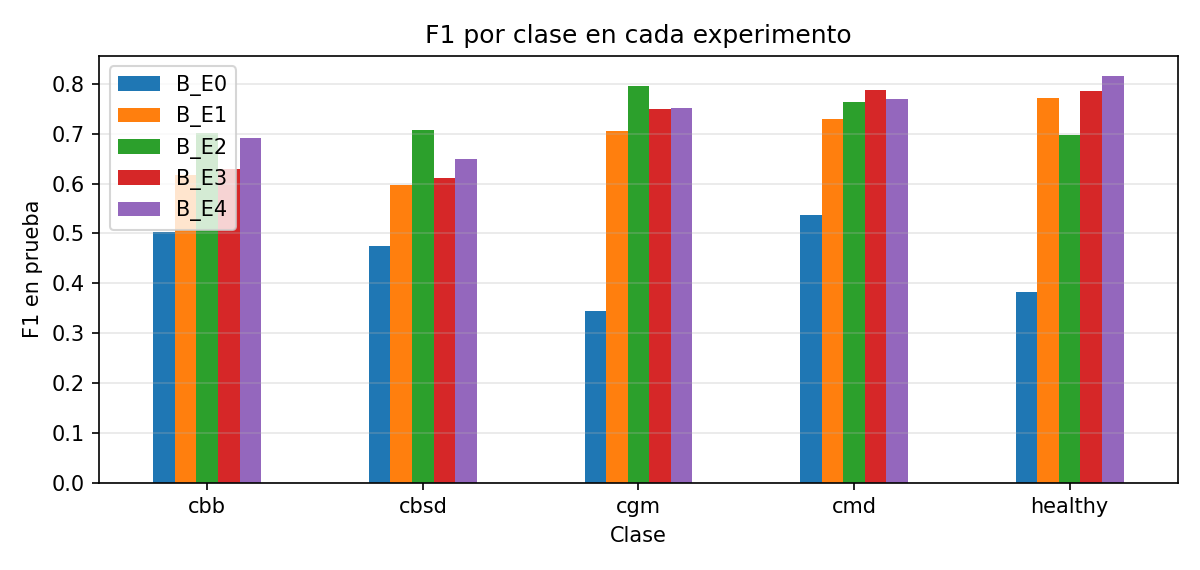

In [6]:
from src import analisis
from IPython.display import Image as Mostrar, display
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
B = ('B_E0', 'B_E1', 'B_E2', 'B_E3', 'B_E4')
consolidada = analisis.graficas_comparacion(B)
print(consolidada.drop(columns=['Dispositivo']).to_string(index=False))
print('\nF1 por clase'); print(analisis.tabla_por_clase(B, 'f1').to_string())
print('\nRecall por clase'); print(analisis.tabla_por_clase(B, 'recall').to_string())
display(Mostrar('resultados/comparacion_f1_por_clase_balanceada.png'))

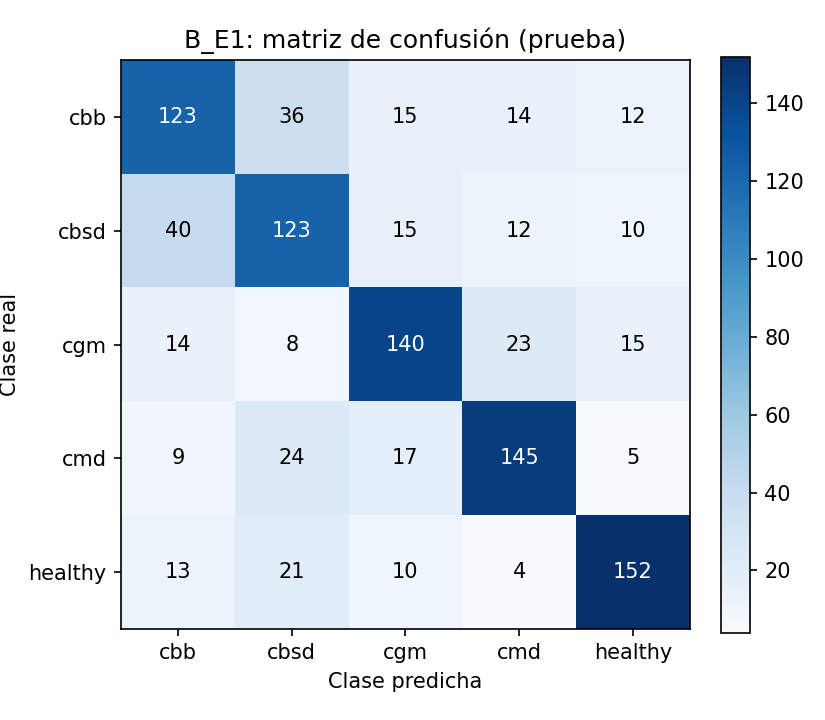

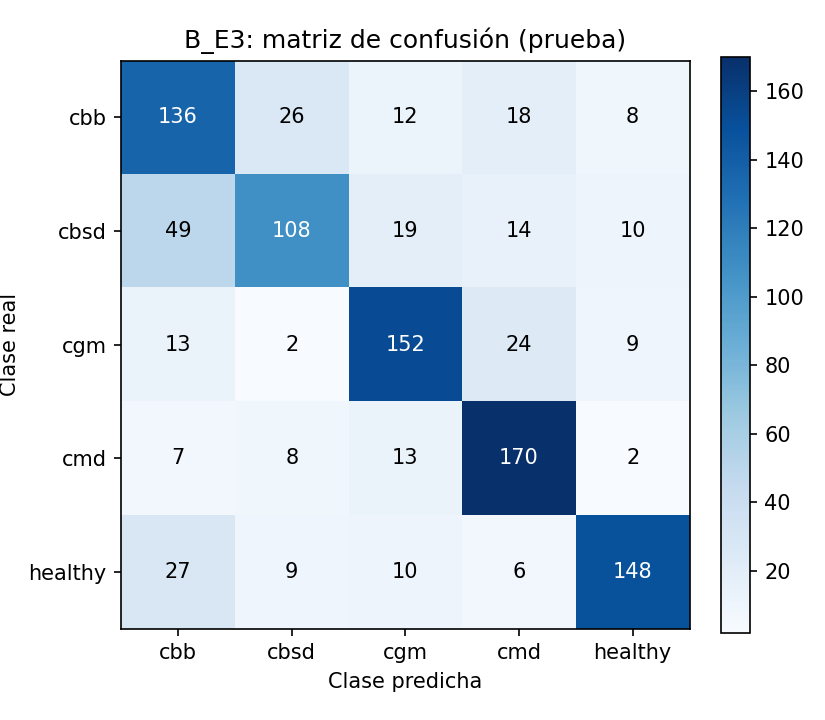

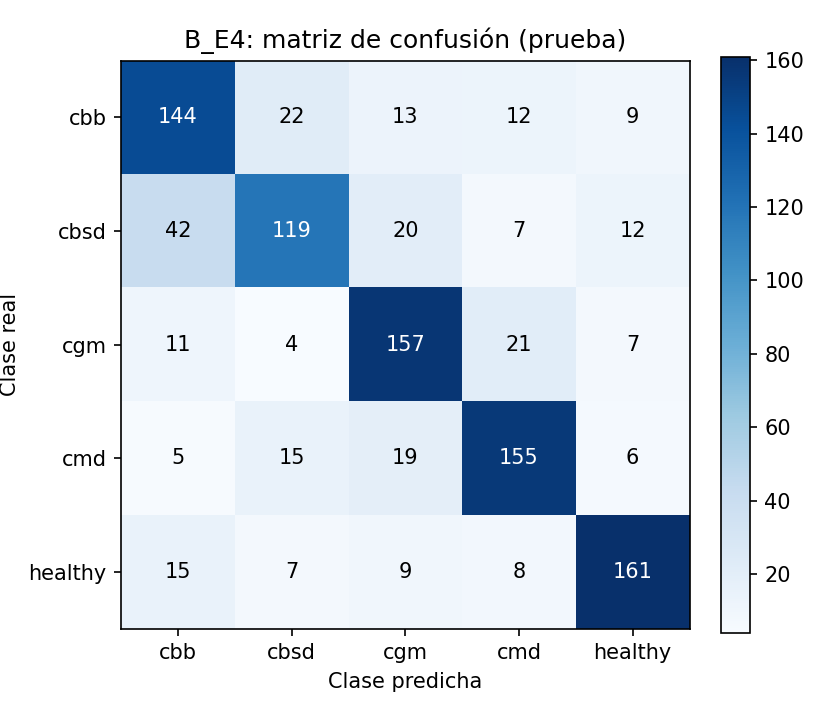

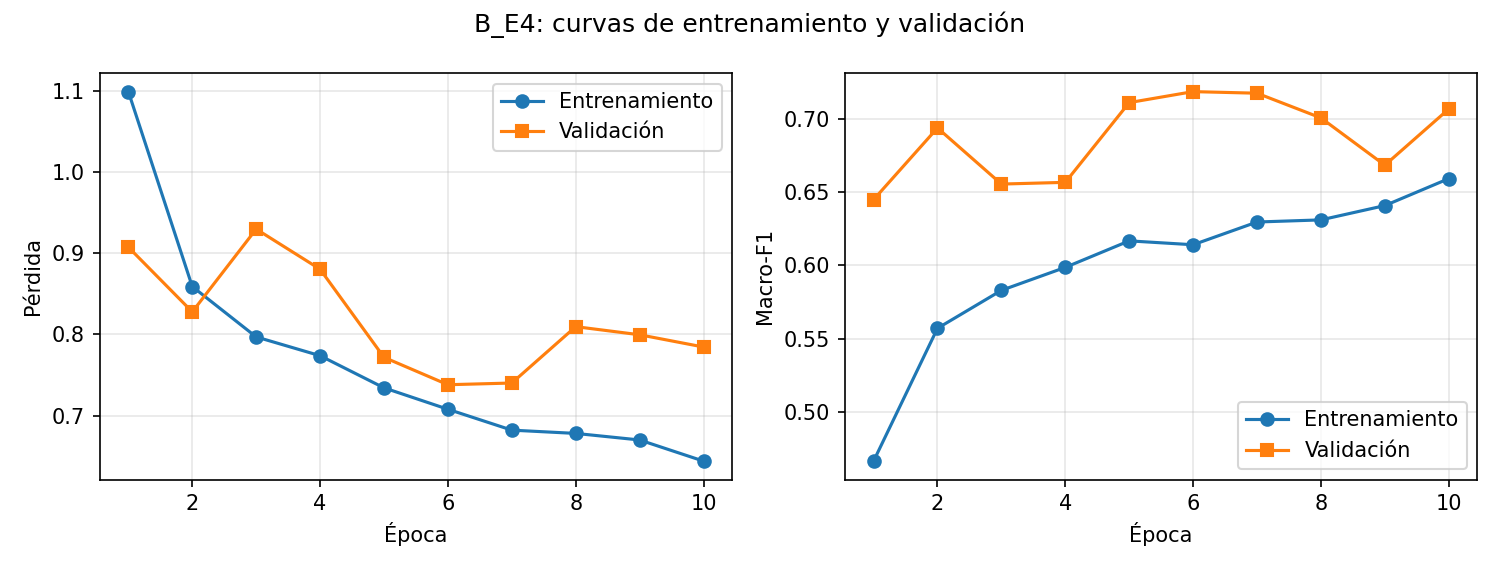

In [7]:
for exp in ('B_E1', 'B_E3', 'B_E4'):
    display(Mostrar(f'resultados/{exp}/matriz_confusion.png'))
display(Mostrar('resultados/B_E4/curvas.png'))

## 5. Errores de E4

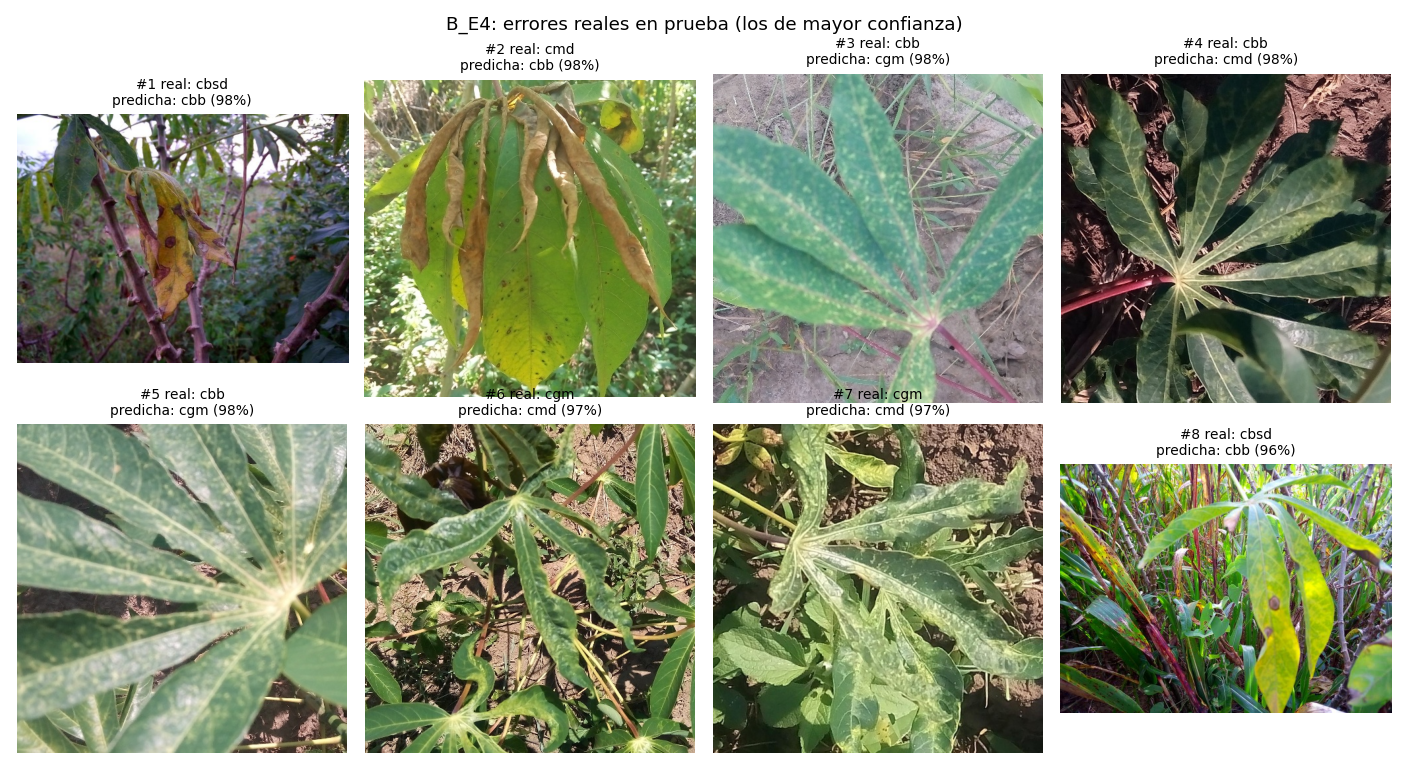

,ruta,real,predicha,confianza
0,validation/cbsd/validation-cbsd-294.jpg,cbsd,cbb,0.9839
1,train/cmd/train-cmd-1989.jpg,cmd,cbb,0.9824
2,train/cbb/train-cbb-59.jpg,cbb,cgm,0.9809
3,validation/cbb/validation-cbb-149.jpg,cbb,cmd,0.9790
4,train/cbb/train-cbb-163.jpg,cbb,cgm,0.9756
5,test/cgm/test-cgm-23.jpg,cgm,cmd,0.9728
6,train/cgm/train-cgm-285.jpg,cgm,cmd,0.9685
7,train/cbsd/train-cbsd-255.jpg,cbsd,cbb,0.9635


In [8]:
err = analisis.galeria_errores('B_E4', n=8)
display(Mostrar('resultados/B_E4/galeria_errores.png'))
err[['ruta', 'real', 'predicha', 'confianza']]

## 6. (Opcional) Estabilidad de E1, E3 y E4 con semillas 1 y 2
Unos 60 minutos más. Ejecutar solo si hay tiempo de GPU.

In [9]:
EJECUTAR_SEMILLAS = False
if EJECUTAR_SEMILLAS:
    for s in (1, 2):
        for exp in ('E1', 'E3', 'E4'):
            ejecutar(exp, cfg=cfg, semilla=s)
    detalle, resumen = analisis.estabilidad(('B_E1', 'B_E3', 'B_E4'))
    display(detalle); display(resumen)

In [10]:
from src.comun import cargar_config
from src.entrenar import ejecutar
from src import analisis
cfg = cargar_config()
cfg['protocolo']['particion'] = 'balanceada'
for s in (1, 2):
    for exp in ('E1', 'E3', 'E4'):
        ejecutar(exp, cfg=cfg, semilla=s)
detalle, resumen = analisis.estabilidad(('B_E1', 'B_E3', 'B_E4'))
display(detalle); display(resumen)

[2026-11-25 05:17:15] === B_E1_s1: Backbone A congelado, solo cabeza ===
[2026-11-25 05:17:15] Dispositivo: Tesla T4 | semilla: 1
[2026-11-25 05:17:15] Partición: balanceada
[2026-11-25 05:17:15] Imágenes: train=7337 val=1000 test=1000
[2026-11-25 05:17:16] Parámetros: 11,179,077 totales, 2,565 entrenables, 44.75 MB
[2026-11-25 05:18:14] Época  1/10 | train pérdida 1.2448 F1 0.4167 | val pérdida 1.0292 F1 0.6211 acc 0.6240  <- mejor hasta ahora (guardado)
[2026-11-25 05:19:15] Época  2/10 | train pérdida 0.9962 F1 0.5139 | val pérdida 0.9442 F1 0.6580 acc 0.6620  <- mejor hasta ahora (guardado)
[2026-11-25 05:20:15] Época  3/10 | train pérdida 0.9420 F1 0.5274 | val pérdida 0.8580 F1 0.6738 acc 0.6760  <- mejor hasta ahora (guardado)
[2026-11-25 05:21:15] Época  4/10 | train pérdida 0.8867 F1 0.5371 | val pérdida 0.8697 F1 0.6664 acc 0.6720
[2026-11-25 05:22:14] Época  5/10 | train pérdida 0.8686 F1 0.5444 | val pérdida 0.8370 F1 0.6757 acc 0.6820  <- mejor hasta ahora (guardado)
[2026

,experimento,ejecucion,macro_f1,accuracy
0,B_E1,B_E1,0.683827,0.683
1,B_E1,B_E1_s1,0.685597,0.686
2,B_E1,B_E1_s2,0.660332,0.659
3,B_E3,B_E3,0.712496,0.714
4,B_E3,B_E3_s1,0.724028,0.724
5,B_E3,B_E3_s2,0.720189,0.720
6,B_E4,B_E4,0.734953,0.736
7,B_E4,B_E4_s1,0.740361,0.742
8,B_E4,B_E4_s2,0.731985,0.735


macro_f1                               accuracy                            
                mean     std     min     max count     mean     std    min    max count
experimento                                                                            
B_E1          0.6766  0.0141  0.6603  0.6856     3   0.6760  0.0148  0.659  0.686     3
B_E3          0.7189  0.0059  0.7125  0.7240     3   0.7193  0.0050  0.714  0.724     3
B_E4          0.7358  0.0042  0.7320  0.7404     3   0.7377  0.0038  0.735  0.742     3